# Studi Kasus Model Fuzzy, Clustering Fuzzy, dan Estimasi Parameter
## Prediksi Dini Indeks Standar Pencemar Udara (ISPU) DKI Jakarta ($t+1$) Menggunakan Takagi-Sugeno Orde-1, Fuzzy C-Means, dan Hybrid Learning (LSE–Gradient Descent)

- **Mata Kuliah:** Komputasi Lunak
- **Program Studi:** Informatika, Fakultas Sains dan Matematika, Universitas Diponegoro
- **Nama:** Menza Isaiah Tampubolon
- **NIM:** 24060124140138

Notebook ini bersifat **mandiri (*self-contained*)** dan siap dijalankan langsung di **Google Colab** maupun Jupyter lokal. Seluruh algoritma inti (**Fuzzy C-Means**, **Takagi-Sugeno Orde-1**, **Regularized LSE**, dan **Hybrid Learning**) diimplementasikan dari dasar menggunakan `NumPy` agar setiap persamaan matematis transparan dan dapat diverifikasi.


In [1]:
import io
import json
from pathlib import Path
from urllib.parse import quote
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#FAFAFA",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": "--",
})
print("Lingkungan siap. NumPy:", np.__version__, "| Pandas:", pd.__version__)


Lingkungan siap. NumPy: 2.2.3 | Pandas: 2.2.3


## 1. Akuisisi & Prapemrosesan Data ISPU DKI Jakarta
Sumber data resmi berasal dari **Dinas Lingkungan Hidup (DLH) Provinsi DKI Jakarta / Portal Satu Data Jakarta** tahun 2021 untuk 5 Stasiun Pemantau Kualitas Udara (SPKU): `DKI1 (Bunderan HI)`, `DKI2 (Kelapa Gading)`, `DKI3 (Jagakarsa)`, `DKI4 (Lubang Buaya)`, dan `DKI5 (Kebon Jeruk)`.

- Jika berkas lokal `data/processed/ispu_dki_nextday.csv` tersedia, notebook memuatnya secara langsung; jika dijalankan di **Google Colab**, notebook otomatis mengunduh 12 berkas CSV bulanan resmi SPKU 2021 dari repositori publik.
- Pemasangan target $y_{t+1} = \text{ISPU}_{\max}(s, t+1)$ dilakukan **ketat di dalam masing-masing stasiun $s$** hanya apabila selisih tanggal tepat **1 hari** (`delta_days == 1`) untuk mencegah kebocoran data (*zero data leakage*).


In [2]:
FEATURE_COLS = ["pm10", "pm25", "so2", "co", "o3", "no2"]
FEATURE_LABELS = {"pm10": "PM10", "pm25": "PM2.5", "so2": "SO2", "co": "CO", "o3": "O3", "no2": "NO2"}
CANONICAL_COLS = ["tanggal", "stasiun", "pm10", "pm25", "so2", "co", "o3", "no2", "max", "critical", "categori"]
MONTHS_ID = ["januari", "februari", "maret", "april", "mei", "juni", "juli", "agustus", "september", "oktober", "november", "desember"]

def load_paired_ispu_data():
    local_candidates = [
        Path("data/processed/ispu_dki_nextday.csv"),
        Path("../data/processed/ispu_dki_nextday.csv"),
    ]
    for p in local_candidates:
        if p.exists():
            df = pd.read_csv(p)
            df["tanggal"] = pd.to_datetime(df["tanggal"])
            df["next_tanggal"] = pd.to_datetime(df["next_tanggal"])
            print(f"Memuat dataset terproses lokal: {p} ({len(df)} baris)")
            return df

    print("Mengunduh 12 berkas bulanan SPKU DKI Jakarta 2021 dari cermin publik GitHub...")
    base = "https://raw.githubusercontent.com/Rendika7/NLP_ISPU_DKI_JAKARTA_2021/main/"
    frames = []
    for m in MONTHS_ID:
        rel_path = f"UAS - TUBES/Dataset/indeks-standar-pencemar-udara-di-spku-bulan-{m}-tahun-2021.csv"
        url = base + quote(rel_path)
        with urllib.request.urlopen(url, timeout=20) as resp:
            part = pd.read_csv(io.BytesIO(resp.read()))
        cols = [str(c).strip().lower() for c in part.columns]
        part.columns = cols
        # Perbaikan header bergeser pada CSV resmi Juni & Juli 2021
        if "location" in cols and "stasiun" not in cols and len(cols) == 11:
            if any("DKI" in str(v) for v in part["pm10"].dropna().head(10)):
                part.columns = CANONICAL_COLS
        frames.append(part)

    raw = pd.concat(frames, ignore_index=True)
    raw["tanggal"] = pd.to_datetime(raw["tanggal"], errors="coerce")
    raw["stasiun"] = raw["stasiun"].astype(str).str.strip()
    for col in [*FEATURE_COLS, "max"]:
        raw[col] = pd.to_numeric(raw[col], errors="coerce")
    raw["categori"] = raw["categori"].astype(str).str.strip().str.upper()

    valid = raw["tanggal"].notna() & (raw["stasiun"] != "") & (raw["stasiun"] != "nan")
    for col in [*FEATURE_COLS, "max"]:
        valid &= raw[col].notna() & (raw[col] >= 0) & (raw[col] <= 500)
    clean = raw.loc[valid].sort_values(["stasiun", "tanggal"]).drop_duplicates(["stasiun", "tanggal"]).reset_index(drop=True)

    clean["next_tanggal"] = clean.groupby("stasiun")["tanggal"].shift(-1)
    clean["target_ispu_next"] = clean.groupby("stasiun")["max"].shift(-1)
    clean["target_category_next"] = clean.groupby("stasiun")["categori"].shift(-1)
    paired = clean.loc[(clean["next_tanggal"] - clean["tanggal"]).dt.days == 1].sort_values(["tanggal", "stasiun"]).reset_index(drop=True)
    print(f"Dataset bersih berpasangan (t -> t+1): {len(paired)} baris")
    return paired

paired_df = load_paired_ispu_data()
display_cols = ["tanggal", "stasiun", *FEATURE_COLS, "max", "target_ispu_next", "target_category_next"]
print(paired_df[display_cols].head())
print("\nStatistik Deskriptif:")
print(paired_df[[*FEATURE_COLS, "max", "target_ispu_next"]].describe().round(2))


Memuat dataset terproses lokal: ..\data\processed\ispu_dki_nextday.csv (1444 baris)
     tanggal             stasiun  pm10  pm25   so2    co    o3   no2   max  \
0 2021-01-01  DKI1 (Bunderan HI)  38.0  53.0  29.0   6.0  31.0  13.0  53.0   
1 2021-01-01    DKI3 (Jagakarsa)  43.0  56.0  15.0  10.0  33.0   5.0  56.0   
2 2021-01-02  DKI1 (Bunderan HI)  27.0  46.0  27.0   7.0  47.0   7.0  47.0   
3 2021-01-02    DKI3 (Jagakarsa)  58.0  86.0  15.0  22.0  38.0   5.0  86.0   
4 2021-01-03  DKI1 (Bunderan HI)  44.0  58.0  25.0   7.0  40.0  13.0  58.0   

   target_ispu_next target_category_next  
0              47.0                 BAIK  
1              86.0               SEDANG  
2              58.0               SEDANG  
3              93.0               SEDANG  
4              48.0                 BAIK  

Statistik Deskriptif:
          pm10     pm25      so2       co       o3      no2      max  \
count  1444.00  1444.00  1444.00  1444.00  1444.00  1444.00  1444.00   
mean     52.88    78.3

In [3]:
# Pembagian Data Kronologis (70% Train / 15% Validation / 15% Test) & Standardisasi Z-Score
unique_dates = np.array(sorted(paired_df["tanggal"].unique()))
tr_end = int(np.floor(len(unique_dates) * 0.70))
va_end = int(np.floor(len(unique_dates) * 0.85))

train_df = paired_df[paired_df["tanggal"].isin(set(unique_dates[:tr_end]))].reset_index(drop=True)
val_df   = paired_df[paired_df["tanggal"].isin(set(unique_dates[tr_end:va_end]))].reset_index(drop=True)
test_df  = paired_df[paired_df["tanggal"].isin(set(unique_dates[va_end:]))].reset_index(drop=True)

X_train = train_df[FEATURE_COLS].to_numpy(dtype=float)
y_train = train_df["target_ispu_next"].to_numpy(dtype=float)
X_val   = val_df[FEATURE_COLS].to_numpy(dtype=float)
y_val   = val_df["target_ispu_next"].to_numpy(dtype=float)
X_test  = test_df[FEATURE_COLS].to_numpy(dtype=float)
y_test  = test_df["target_ispu_next"].to_numpy(dtype=float)

# Fit Z-score scaler HANYA pada X_train
x_mean = X_train.mean(axis=0)
x_std  = np.where(X_train.std(axis=0) < 1e-8, 1.0, X_train.std(axis=0))

X_tr_s = (X_train - x_mean) / x_std
X_va_s = (X_val   - x_mean) / x_std
X_te_s = (X_test  - x_mean) / x_std

print(f"Train: {len(train_df)} ({train_df['tanggal'].min().date()} s.d. {train_df['tanggal'].max().date()})")
print(f"Val  : {len(val_df)} ({val_df['tanggal'].min().date()} s.d. {val_df['tanggal'].max().date()})")
print(f"Test : {len(test_df)} ({test_df['tanggal'].min().date()} s.d. {test_df['tanggal'].max().date()})")


Train: 1065 (2021-01-01 s.d. 2021-09-11)
Val  : 175 (2021-09-12 s.d. 2021-11-05)
Test : 204 (2021-11-06 s.d. 2021-12-30)


## 2. Clustering Fuzzy: Fuzzy C-Means (FCM) & Validitas Cluster
Fungsi objektif Fuzzy C-Means (Bezdek, 1981):
$$J_m(U, V) = \sum_{k=1}^{N}\sum_{i=1}^{c} u_{ik}^m \|\mathbf{x}_k - \mathbf{v}_i\|_2^2, \quad m = 2.0$$
Pembaruan derajat keanggotaan dan pusat cluster dilakukan secara iteratif hingga $\|U^{(t)} - U^{(t-1)}\|_\infty < 10^{-5}$, lalu dievaluasi dengan **Partition Coefficient (PC)**, **Partition Entropy (PE)**, dan **Xie-Beni Index (XB)**.


In [4]:
class FuzzyCMeans:
    def __init__(self, n_clusters=3, m=2.0, max_iter=300, tol=1e-5, random_state=42):
        self.n_clusters = n_clusters
        self.m = m
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

    @staticmethod
    def _sq_dist(X, centers):
        diff = centers[:, np.newaxis, :] - X[np.newaxis, :, :]
        return np.sum(diff * diff, axis=2)

    def _u_from_sq_dist(self, sq_dist):
        c, n = sq_dist.shape
        u = np.zeros((c, n), dtype=float)
        zero_mask = sq_dist <= 1e-24
        has_zero = np.any(zero_mask, axis=0)
        for k in np.where(has_zero)[0]:
            zeros = zero_mask[:, k]
            u[zeros, k] = 1.0 / np.sum(zeros)
        nz = ~has_zero
        if np.any(nz):
            d_nz = np.sqrt(sq_dist[:, nz])
            inv_d = np.power(d_nz, -2.0 / (self.m - 1.0))
            u[:, nz] = inv_d / np.sum(inv_d, axis=0, keepdims=True)
        return u

    def fit(self, X):
        rng = np.random.default_rng(self.random_state)
        u = rng.dirichlet(np.ones(self.n_clusters), size=len(X)).T
        self.jm_history_ = []
        for it in range(1, self.max_iter + 1):
            um = u ** self.m
            centers = (um @ X) / np.maximum(np.sum(um, axis=1, keepdims=True), 1e-12)
            sq_dist = self._sq_dist(X, centers)
            self.jm_history_.append(float(np.sum(um * sq_dist)))
            u_new = self._u_from_sq_dist(sq_dist)
            delta = float(np.max(np.abs(u_new - u)))
            u = u_new
            self.n_iter_ = it
            if delta < self.tol:
                break
        um = u ** self.m
        centers = (um @ X) / np.maximum(np.sum(um, axis=1, keepdims=True), 1e-12)
        order = np.argsort(np.mean(centers, axis=1))
        self.centers_ = centers[order]
        self.u_ = u[order]
        return self

    def predict_membership(self, X):
        return self._u_from_sq_dist(self._sq_dist(X, self.centers_))

    def validity_metrics(self, X):
        n = len(X)
        u = self.u_
        pc = float(np.sum(u * u) / n)
        pe = float(-np.sum(u * np.log(np.clip(u, 1e-12, 1.0))) / n)
        jm = float(np.sum((u ** self.m) * self._sq_dist(X, self.centers_)))
        c_sq = self._sq_dist(self.centers_, self.centers_)
        np.fill_diagonal(c_sq, np.inf)
        xb = float(jm / (n * max(float(np.min(c_sq)), 1e-12)))
        return {"pc": pc, "pe": pe, "xb": xb, "jm": jm, "n_iter": self.n_iter_}


## 3. Model Fuzzy Takagi-Sugeno Orde-1 & Hybrid Learning (LSE + Gradient Descent)
- **Premis Gaussian:** $\mu_{ij}(x_j) = \exp\!\left(-\frac{(x_j - v_{ij})^2}{2\sigma_{ij}^2}\right)$
- **Konsekuen Linear Orde-1:** $f_i(\mathbf{x}) = p_{i0} + \sum_{j=1}^{6} p_{ij} x_j$
- **Hybrid Learning (Jang, 1993):**
  1. *Forward Pass:* Menyelesaikan parameter konsekuen $\boldsymbol{\theta}$ secara eksak menggunakan Regularized LSE $\hat{\boldsymbol{\theta}} = (\mathbf{A}^\top\mathbf{A} + \lambda\mathbf{I})^{-1}\mathbf{A}^\top\mathbf{y}$.
  2. *Backward Pass:* Memperbarui parameter premis $(v_{ij}, \log\sigma_{ij})$ menggunakan Gradient Descent adaptif dengan *early stopping* berbasis Validation RMSE.


In [5]:
class TakagiSugenoHybrid:
    def __init__(self, n_clusters, n_features, ridge_lambda=50.0, sigma_min=0.25, sigma_max=5.0):
        self.n_clusters = n_clusters
        self.n_features = n_features
        self.ridge_lambda = ridge_lambda
        self.sigma_min = sigma_min
        self.sigma_max = sigma_max
        self.history_ = []

    def initialize_from_fcm(self, X_train, u_train, centers, m=2.0):
        um = u_train ** m
        denom = np.maximum(np.sum(um, axis=1, keepdims=True), 1e-12)
        sq_diff = (X_train[np.newaxis, :, :] - centers[:, np.newaxis, :]) ** 2
        sigmas = np.clip(np.sqrt(np.maximum(np.sum(um[:, :, np.newaxis] * sq_diff, axis=1) / denom, 1e-12)), self.sigma_min, self.sigma_max)
        self.init_centers_, self.init_sigmas_ = centers.copy(), sigmas.copy()
        self.centers_, self.sigmas_ = centers.copy(), sigmas.copy()
        return self

    def _forward_premise(self, X):
        diff = X[:, np.newaxis, :] - self.centers_[np.newaxis, :, :]
        log_mu = -0.5 * (diff * diff) / (self.sigmas_[np.newaxis, :, :] ** 2)
        mu = np.exp(np.clip(log_mu, -700.0, 0.0))
        log_w = np.sum(log_mu, axis=2)
        shifted = np.exp(log_w - np.max(log_w, axis=1, keepdims=True))
        w_bar = shifted / np.sum(shifted, axis=1, keepdims=True)
        return mu, log_w, w_bar

    def fit_zero_order(self, X_train, y_train):
        _, _, w_bar = self._forward_premise(X_train)
        conseq = np.zeros((self.n_clusters, self.n_features + 1), dtype=float)
        conseq[:, 0] = (w_bar.T @ y_train) / np.maximum(np.sum(w_bar, axis=0), 1e-12)
        self.consequents_ = conseq
        return self

    def fit_lse(self, X_train, y_train, ridge_lambda=None):
        lam = self.ridge_lambda if ridge_lambda is None else ridge_lambda
        self.ridge_lambda = lam
        _, _, w_bar = self._forward_premise(X_train)
        X_aug = np.hstack([np.ones((len(X_train), 1)), X_train])
        A = (w_bar[:, :, np.newaxis] * X_aug[:, np.newaxis, :]).reshape(len(X_train), -1)
        theta = np.linalg.solve(A.T @ A + lam * np.eye(A.shape[1]), A.T @ y_train)
        self.consequents_ = theta.reshape(self.n_clusters, self.n_features + 1)
        return self

    def _predict_comp(self, X):
        _, _, w_bar = self._forward_premise(X)
        X_aug = np.hstack([np.ones((len(X), 1)), X])
        rule_out = X_aug @ self.consequents_.T
        return np.sum(w_bar * rule_out, axis=1), w_bar, rule_out

    def predict(self, X):
        return self._predict_comp(X)[0]

    def fit_hybrid(self, X_tr, y_tr, X_va, y_va, epochs=150, lr=0.05, patience=30):
        self.fit_lse(X_tr, y_tr)
        best_va = float(np.sqrt(np.mean((y_va - self.predict(X_va)) ** 2)))
        best_c, best_s, best_q = self.centers_.copy(), self.sigmas_.copy(), self.consequents_.copy()
        tr0 = float(np.sqrt(np.mean((y_tr - self.predict(X_tr)) ** 2)))
        self.history_ = [{"epoch": 0, "train_rmse": tr0, "val_rmse": best_va}]

        cur_lr, prev_loss, streak, wait = lr, 0.5 * tr0 ** 2, 0, 0
        for ep in range(1, epochs + 1):
            y_pred, w_bar, rule_out = self._predict_comp(X_tr)
            err = y_pred - y_tr
            dL_dlog_w = (err[:, None] / len(X_tr)) * w_bar * (rule_out - y_pred[:, None])
            diff = X_tr[:, None, :] - self.centers_[None, :, :]
            inv_s2 = 1.0 / (self.sigmas_[None, :, :] ** 2)
            gv = np.sum(dL_dlog_w[:, :, None] * diff * inv_s2, axis=0)
            gs = np.sum(dL_dlog_w[:, :, None] * (diff * diff) * inv_s2, axis=0)
            gn = float(np.sqrt(np.sum(gv ** 2) + np.sum(gs ** 2)))
            if gn > 5.0:
                gv, gs = gv * (5.0 / gn), gs * (5.0 / gn)

            self.centers_ = self.centers_ - cur_lr * gv
            self.sigmas_ = np.clip(np.exp(np.log(self.sigmas_) - cur_lr * gs), self.sigma_min, self.sigma_max)
            self.fit_lse(X_tr, y_tr)

            tr_rmse = float(np.sqrt(np.mean((y_tr - self.predict(X_tr)) ** 2)))
            va_rmse = float(np.sqrt(np.mean((y_va - self.predict(X_va)) ** 2)))
            self.history_.append({"epoch": ep, "train_rmse": tr_rmse, "val_rmse": va_rmse})
            if va_rmse < best_va - 1e-8:
                best_va, best_c, best_s, best_q, wait = va_rmse, self.centers_.copy(), self.sigmas_.copy(), self.consequents_.copy(), 0
            else:
                wait += 1
            loss_new = 0.5 * tr_rmse ** 2
            if loss_new < prev_loss - 1e-10:
                streak += 1
                if streak >= 4:
                    cur_lr, streak = min(cur_lr * 1.1, 0.5), 0
            else:
                cur_lr, streak = max(cur_lr * 0.5, 1e-5), 0
            prev_loss = loss_new
            if wait >= patience:
                break
        self.centers_, self.sigmas_, self.consequents_ = best_c, best_s, best_q
        return self


## 4. Seleksi Jumlah Cluster ($c^*$) & Pelatihan Studi Ablasi


In [6]:
def ispu_to_category(score):
    if score <= 50.0: return "Baik"
    if score <= 100.0: return "Sedang"
    if score <= 200.0: return "Tidak Sehat"
    if score <= 300.0: return "Sangat Tidak Sehat"
    return "Berbahaya"

def compute_metrics(y_true, y_pred):
    err = y_pred - y_true
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mae = float(np.mean(np.abs(err)))
    r2 = float(1.0 - np.sum(err ** 2) / np.sum((y_true - np.mean(y_true)) ** 2))
    mape = float(np.mean(np.abs(err) / np.maximum(np.abs(y_true), 1.0)) * 100.0)
    cat_acc = float(np.mean([ispu_to_category(t) == ispu_to_category(p) for t, p in zip(y_true, y_pred)]))
    return {"RMSE": rmse, "MAE": mae, "R2": r2, "MAPE (%)": mape, "Akurasi Kategori": cat_acc}

sweep_rows = []
for c in [2, 3, 4, 5, 6]:
    fcm_c = FuzzyCMeans(n_clusters=c, m=2.0, random_state=42).fit(X_tr_s)
    m_val = fcm_c.validity_metrics(X_tr_s)
    best_lam, best_v = 1.0, float("inf")
    for lam in [0.1, 1.0, 5.0, 10.0, 25.0, 50.0, 100.0]:
        tmp = TakagiSugenoHybrid(c, 6, ridge_lambda=lam).initialize_from_fcm(X_tr_s, fcm_c.u_, fcm_c.centers_).fit_lse(X_tr_s, y_train)
        v_rmse = float(np.sqrt(np.mean((y_val - tmp.predict(X_val_s if 'X_val_s' in globals() else X_va_s)) ** 2)))
        if v_rmse < best_v:
            best_v, best_lam = v_rmse, lam
    sweep_rows.append({"c": c, **m_val, "best_lambda_lse": best_lam, "lse_val_rmse": best_v})

sweep_df = pd.DataFrame(sweep_rows)
print(sweep_df.round(4).to_string(index=False))

best_c_row = min(sweep_rows, key=lambda r: (round(r["lse_val_rmse"], 4), r["xb"]))
c_opt = int(best_c_row["c"])
fcm_opt = FuzzyCMeans(n_clusters=c_opt, m=2.0, random_state=42).fit(X_tr_s)

# Seleksi ridge_lambda* berbasis Hybrid Validation RMSE
lam_opt, best_h_val = 25.0, float("inf")
for lam in [1.0, 5.0, 10.0, 25.0, 50.0, 100.0]:
    cand = TakagiSugenoHybrid(c_opt, 6, ridge_lambda=lam).initialize_from_fcm(X_tr_s, fcm_opt.u_, fcm_opt.centers_)
    cand.fit_hybrid(X_tr_s, y_train, X_va_s, y_val, epochs=150, lr=0.05, patience=30)
    vr = float(np.sqrt(np.mean((y_val - cand.predict(X_va_s)) ** 2)))
    if vr < best_h_val:
        best_h_val, lam_opt = vr, lam

print(f"\nTerpilih c* = {c_opt}, ridge_lambda* = {lam_opt} (Val RMSE Hybrid = {best_h_val:.4f})")

# Model Ablasi & Pembanding Konvensional
pers_te = test_df["max"].to_numpy(dtype=float)
A_tr_ols = np.hstack([np.ones((len(X_tr_s), 1)), X_tr_s])
A_te_ols = np.hstack([np.ones((len(X_te_s), 1)), X_te_s])
beta_ols = np.linalg.solve(A_tr_ols.T @ A_tr_ols + 1e-6 * np.eye(7), A_tr_ols.T @ y_train)
ols_te = A_te_ols @ beta_ols

ts0 = TakagiSugenoHybrid(c_opt, 6, lam_opt).initialize_from_fcm(X_tr_s, fcm_opt.u_, fcm_opt.centers_).fit_zero_order(X_tr_s, y_train)
ts1 = TakagiSugenoHybrid(c_opt, 6, lam_opt).initialize_from_fcm(X_tr_s, fcm_opt.u_, fcm_opt.centers_).fit_lse(X_tr_s, y_train)
ts2 = TakagiSugenoHybrid(c_opt, 6, lam_opt).initialize_from_fcm(X_tr_s, fcm_opt.u_, fcm_opt.centers_).fit_hybrid(X_tr_s, y_train, X_va_s, y_val)

ablation_df = pd.DataFrame({
    "Persistence (ISPU_t)": compute_metrics(y_test, pers_te),
    "Regresi Linear (OLS)": compute_metrics(y_test, ols_te),
    "Tahap 0: FCM + Sugeno-0": compute_metrics(y_test, ts0.predict(X_te_s)),
    "Tahap 1: FCM + TSK-1 (LSE)": compute_metrics(y_test, ts1.predict(X_te_s)),
    "Tahap 2: FCM + TSK-1 (Hybrid)": compute_metrics(y_test, ts2.predict(X_te_s)),
}).T
print("\n--- Hasil Evaluasi Data Uji (Test Set) ---")
print(ablation_df.round(4).to_string())


 c     pc     pe     xb        jm  n_iter  best_lambda_lse  lse_val_rmse
 2 0.5938 0.5934 0.7590 3101.3231      44             25.0       13.6816
 3 0.4636 0.9110 0.6684 2020.4477      50              5.0       14.2194
 4 0.3775 1.1562 0.8322 1502.4526      84              1.0       14.4295
 5 0.3251 1.3428 0.7323 1193.5154      72              1.0       14.4994
 6 0.2869 1.4996 0.8544  989.3879      97              1.0       14.9706



Terpilih c* = 2, ridge_lambda* = 50.0 (Val RMSE Hybrid = 13.2142)

--- Hasil Evaluasi Data Uji (Test Set) ---
                                  RMSE      MAE      R2  MAPE (%)  Akurasi Kategori
Persistence (ISPU_t)           21.5199  16.2549 -0.2259   27.0244            0.7010
Regresi Linear (OLS)           19.2747  14.4469  0.0165   26.1724            0.7843
Tahap 0: FCM + Sugeno-0        22.3855  17.7452 -0.3265   34.1616            0.7647
Tahap 1: FCM + TSK-1 (LSE)     20.6842  15.4189 -0.1326   27.1113            0.7549
Tahap 2: FCM + TSK-1 (Hybrid)  18.9659  14.0855  0.0478   24.7596            0.7451


## 5. Visualisasi Cluster, Fungsi Keanggotaan, Konvergensi & Prediksi


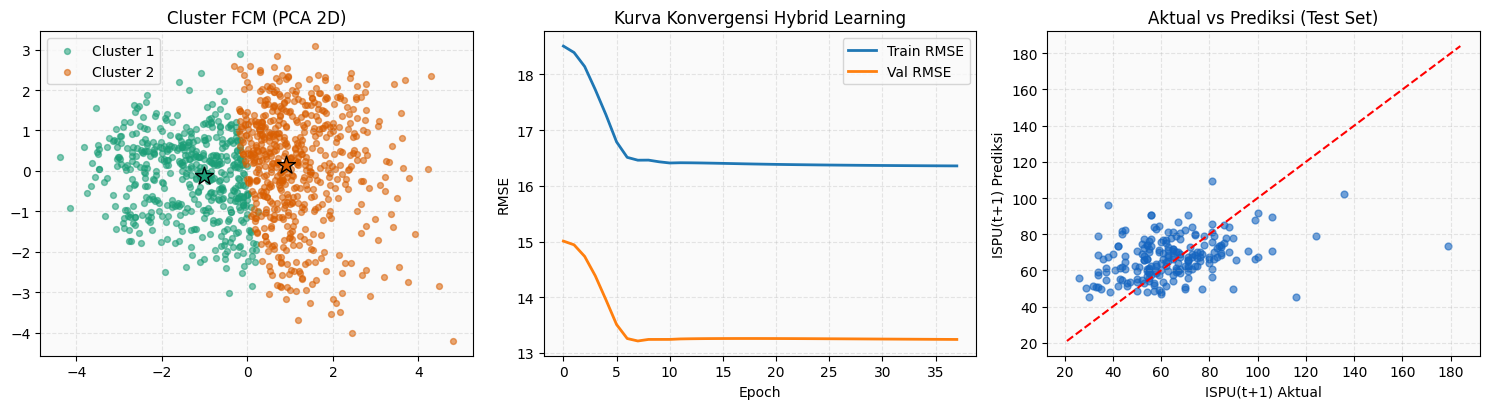

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
# Plot 1: PCA 2D Cluster FCM
pca = PCA(n_components=2, random_state=42).fit(X_tr_s)
X_pca = pca.transform(X_tr_s)
ctr_pca = pca.transform(fcm_opt.centers_)
dom = np.argmax(fcm_opt.u_, axis=0)
colors = ["#1B9E77", "#D95F02", "#7570B3"]
for i in range(c_opt):
    axes[0].scatter(X_pca[dom == i, 0], X_pca[dom == i, 1], s=18, alpha=0.55, color=colors[i], label=f"Cluster {i+1}")
    axes[0].scatter(ctr_pca[i, 0], ctr_pca[i, 1], s=180, marker="*", color=colors[i], edgecolor="black", zorder=5)
axes[0].set_title("Cluster FCM (PCA 2D)")
axes[0].legend()

# Plot 2: Hybrid Convergence
hdf = pd.DataFrame(ts2.history_)
axes[1].plot(hdf["epoch"], hdf["train_rmse"], label="Train RMSE", linewidth=2)
axes[1].plot(hdf["epoch"], hdf["val_rmse"], label="Val RMSE", linewidth=2)
axes[1].set_title("Kurva Konvergensi Hybrid Learning")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("RMSE")
axes[1].legend()

# Plot 3: Test Actual vs Predicted
y_te_pred = ts2.predict(X_te_s)
axes[2].scatter(y_test, y_te_pred, alpha=0.6, s=24, color="#1565C0")
lim = [min(y_test.min(), y_te_pred.min()) - 5, max(y_test.max(), y_te_pred.max()) + 5]
axes[2].plot(lim, lim, "r--", linewidth=1.5)
axes[2].set_title("Aktual vs Prediksi (Test Set)")
axes[2].set_xlabel("ISPU(t+1) Aktual")
axes[2].set_ylabel("ISPU(t+1) Prediksi")
fig.tight_layout()
plt.show()
